# 01. Разведочный анализ (EDA): спрос на наличные в банкоматах

**Цель ноутбука:** понять, от чего зависит, сколько наличных выдаёт банкомат за день, — прежде чем строить модель прогноза.

**Что делаем:**
1. Сворачиваем 12,5 млн транзакций до таблицы «банкомат × день» (DuckDB).
2. Отмечаем дни, когда банкомат был без денег или в простое (не удаляем, только флаг).
3. Присоединяем календарь (праздники, погода, курс) и паспорт банкомата.
4. Смотрим на графики и формулируем выводы.
5. Сохраняем результат в `data/processed/daily.parquet` — это вход для модели.

> Данные синтетические (сгенерированы), но построены на реальной погоде, курсе НБКР и картах Бишкека.

In [1]:
from pathlib import Path
import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

# Корень проекта: ноутбук может запускаться из notebooks/ или из корня
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = ROOT / "data" / "mbank-atm-bishkek"
OUT = ROOT / "data" / "processed"
FIG = ROOT / "reports" / "figures"
OUT.mkdir(parents=True, exist_ok=True)
FIG.mkdir(parents=True, exist_ok=True)

# Оформление графиков: спокойная сетка, тонкие линии, одна палитра на весь ноутбук
BLUE, ORANGE, AQUA, GRAY = "#2a78d6", "#eb6834", "#1baf7a", "#a3a29c"
INK, INK2 = "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.figsize": (11, 4.2), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#d6d5d0", "axes.labelcolor": INK2,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#ebeae6", "grid.linewidth": 0.8,
    "xtick.color": INK2, "ytick.color": INK2, "text.color": INK,
    "legend.frameon": False, "lines.linewidth": 2,
})
mln = mticker.FuncFormatter(lambda x, _: f"{x/1e6:,.0f}".replace(",", " "))
thousands = mticker.FuncFormatter(lambda x, _: f"{x/1e3:,.0f}".replace(",", " "))
pct = mticker.FuncFormatter(lambda x, _: f"{x:+.0%}")

def save(fig, name):
    fig.savefig(FIG / f"{name}.png", bbox_inches="tight")

con = duckdb.connect()
print("Данные:", RAW)

Данные: /Users/aza/Projects/atm-cash-forecast/data/mbank-atm-bishkek


## 1. Агрегация: банкомат × день

Сырые транзакции — это каждая отдельная операция (12,5 млн строк). Для прогноза нам нужна одна строка на **банкомат и день**.

- **`cash_out`** — сколько наличных выдано за день (сумма `dispensed_amount` по снятиям `withdrawal` и `fast_cash`). Это то, что мы будем прогнозировать. Взносы (`deposit`) не считаем — это деньги *в* банкомат, а не из него.
- **`n_txn`** — все операции за день, включая запросы баланса и переводы.
- **`n_cash_txn`** — только снятия наличных.
- **`decline_share`** — доля отказов (любой код ответа, кроме `00`).
- **`n_declined_no_cash`** — отказы с кодом `99` «нет наличных».

Важно: строим **полную сетку** «все банкоматы × все дни» (с момента установки банкомата). Если в какой-то день операций не было, это строка с нулём, а не пропуск — иначе модель никогда не увидит «нулевые» дни.

In [2]:
con.sql(f'''
CREATE OR REPLACE TABLE tx_daily AS
SELECT
    atm_id,
    CAST(date AS DATE)                                                        AS date,
    count(*)                                                                  AS n_txn,
    count(*) FILTER (WHERE txn_type IN ('withdrawal', 'fast_cash'))           AS n_cash_txn,
    coalesce(sum(dispensed_amount)
             FILTER (WHERE txn_type IN ('withdrawal', 'fast_cash')), 0)       AS cash_out,
    avg(CASE WHEN is_approved THEN 0 ELSE 1 END)                              AS decline_share,
    count(*) FILTER (WHERE response_code = '99')                              AS n_declined_no_cash
FROM read_parquet('{RAW}/facts/fact_transactions/**/*.parquet', hive_partitioning = true)
GROUP BY 1, 2
''')

# Полная сетка: каждый банкомат × каждый день начиная с даты установки
con.sql(f'''
CREATE OR REPLACE TABLE grid AS
SELECT a.atm_id, CAST(c.date AS DATE) AS date
FROM read_parquet('{RAW}/dimensions/dim_atm.parquet') a
CROSS JOIN read_parquet('{RAW}/dimensions/dim_calendar.parquet') c
WHERE CAST(c.date AS DATE) >= CAST(a.install_date AS DATE)
''')

print(con.sql("SELECT count(*) AS atm_days_with_txn, sum(n_txn) AS txn FROM tx_daily").df())
print(con.sql("SELECT count(*) AS atm_days_in_grid FROM grid").df())

   atm_days_with_txn         txn
0              82563  12561940.0
   atm_days_in_grid
0             82565


## 2. Дни без денег и простои

Если банкомат пустой или сломан, он выдаёт меньше **не потому, что спрос упал**, а потому что не может выдать. Такие дни нельзя просто удалить (модель должна знать, что они бывают), но и учиться на них «как на обычных» нельзя. Поэтому ставим флаги.

Источники:
- `labels/cash_events` и `fact_atm_status` со статусом `out_of_cash` — банкомат пустой;
- `labels/faults` и `fact_atm_status` со статусами `network_down`, `hardware_fault`, а также «зависания» `stuck` — простой;
- `fact_atm_status` со статусом `low_cash` — денег мало, но банкомат работает (отдельный флаг, это не простой).

Каждый интервал «режем» по дням и считаем, сколько часов он занял в каждом дне.

In [3]:
con.sql(f'''
CREATE OR REPLACE TABLE incidents AS
-- Внимание: least() в DuckDB игнорирует NULL, поэтому ниже везде coalesce(..., 0)
-- UNION (без ALL) убирает дубли: одни и те же события есть и в labels, и в fact_atm_status
SELECT atm_id, start_ts, end_ts, status AS kind
FROM read_parquet('{RAW}/facts/fact_atm_status.parquet')
UNION
SELECT atm_id, start_ts, end_ts, event_type FROM read_parquet('{RAW}/labels/cash_events.parquet')
UNION
SELECT atm_id, start_ts, end_ts, kind FROM read_parquet('{RAW}/labels/faults.parquet')
''')

con.sql('''
CREATE OR REPLACE TABLE incident_days AS
WITH split AS (
    SELECT i.atm_id, i.kind, CAST(d.day AS DATE) AS date,
           epoch(least(i.end_ts, d.day + INTERVAL 1 DAY) - greatest(i.start_ts, d.day)) / 3600 AS hours
    FROM incidents i,
         LATERAL (SELECT unnest(generate_series(date_trunc('day', i.start_ts),
                                                date_trunc('day', i.end_ts),
                                                INTERVAL 1 DAY)) AS day) d
)
SELECT atm_id, date,
       least(24, coalesce(sum(hours) FILTER (WHERE kind = 'out_of_cash'), 0))                               AS out_of_cash_hours,
       least(24, coalesce(sum(hours) FILTER (WHERE kind IN ('network_down', 'hardware_fault', 'stuck')), 0)) AS down_hours,
       least(24, coalesce(sum(hours) FILTER (WHERE kind = 'low_cash'), 0))                                  AS low_cash_hours
FROM split
WHERE hours > 0
GROUP BY 1, 2
''')

print(con.sql("SELECT kind, count(*) AS intervals FROM incidents GROUP BY 1 ORDER BY 2 DESC").df())

             kind  intervals
0        low_cash       9207
1  hardware_fault        367
2    network_down        346
3     out_of_cash        206
4           stuck         14


## 3. Присоединяем календарь и паспорт банкомата

- **Календарь** (`dim_calendar`): день недели, праздники, предпраздничные дни, Рамадан, дни пенсий и зарплат, погода, курс доллара и его скачки.
- **Банкомат** (`dim_atm` + `dim_district`): район и тип района, тип точки (ТЦ, рынок, жилой массив…), улица/помещение, круглосуточный ли, вместимость кассет.

Колонку `base_intensity` из `dim_atm` сознательно **не берём**: это внутренний параметр генератора данных («насколько популярен банкомат»), в реальном банке такого поля нет — модель бы просто подсмотрела ответ.

In [4]:
daily = con.sql(f'''
SELECT
    g.atm_id, g.date,
    -- целевая переменная и операции
    coalesce(t.cash_out, 0)            AS cash_out,
    coalesce(t.n_txn, 0)               AS n_txn,
    coalesce(t.n_cash_txn, 0)          AS n_cash_txn,
    t.decline_share,
    coalesce(t.n_declined_no_cash, 0)  AS n_declined_no_cash,
    -- инциденты (флаги, строки не удаляем)
    coalesce(i.out_of_cash_hours, 0)   AS out_of_cash_hours,
    coalesce(i.down_hours, 0)          AS down_hours,
    coalesce(i.low_cash_hours, 0)      AS low_cash_hours,
    coalesce(i.out_of_cash_hours, 0) > 0                                   AS is_out_of_cash,
    coalesce(i.down_hours, 0) > 0                                          AS is_down,
    coalesce(i.out_of_cash_hours, 0) > 0 OR coalesce(i.down_hours, 0) > 0  AS is_disrupted,
    -- календарь
    isodow(g.date)                     AS dow,          -- 1 = понедельник … 7 = воскресенье
    c.is_weekend, c.is_holiday, c.holiday_name, c.is_pre_holiday, c.is_ramadan,
    c.is_pension_day, c.is_payday, c.season,
    c.temp_avg, c.precip_mm, c.snowfall_mm, c.wind_max,
    c.usd_kgs_rate, c.fx_change_pct, c.fx_shock,
    -- банкомат и район
    a.district_id, d.name AS district_name, d.zone_type,
    a.atm_type, a.placement, a.is_24_7, a.is_recycler, a.supports_fx,
    a.cash_capacity, CAST(a.install_date AS DATE) AS install_date
FROM grid g
LEFT JOIN tx_daily t      USING (atm_id, date)
LEFT JOIN incident_days i USING (atm_id, date)
LEFT JOIN read_parquet('{RAW}/dimensions/dim_calendar.parquet') c ON CAST(c.date AS DATE) = g.date
LEFT JOIN read_parquet('{RAW}/dimensions/dim_atm.parquet')      a ON a.atm_id = g.atm_id
LEFT JOIN read_parquet('{RAW}/dimensions/dim_district.parquet') d ON d.district_id = a.district_id
ORDER BY g.atm_id, g.date
''').df()

daily["date"] = pd.to_datetime(daily["date"])
print(daily.shape)
daily.head()

(82565, 39)


,atm_id,date,cash_out,n_txn,n_cash_txn,decline_share,n_declined_no_cash,out_of_cash_hours,down_hours,low_cash_hours,...,district_id,district_name,zone_type,atm_type,placement,is_24_7,is_recycler,supports_fx,cash_capacity,install_date
0,ATM-0001,2024-01-01,224500.0,73,58,0.027397,0,0.0,0.0,0.0,...,ZN-JAL,Джал,residential,residential,street,True,True,False,4560368,2023-01-21
1,ATM-0001,2024-01-02,247000.0,74,62,0.027027,0,0.0,0.0,0.0,...,ZN-JAL,Джал,residential,residential,street,True,True,False,4560368,2023-01-21
2,ATM-0001,2024-01-03,177500.0,54,47,0.037037,0,0.0,0.0,0.0,...,ZN-JAL,Джал,residential,residential,street,True,True,False,4560368,2023-01-21
3,ATM-0001,2024-01-04,356000.0,114,98,0.052632,0,0.0,0.0,0.0,...,ZN-JAL,Джал,residential,residential,street,True,True,False,4560368,2023-01-21
4,ATM-0001,2024-01-05,89500.0,34,27,0.088235,0,0.0,0.0,0.0,...,ZN-JAL,Джал,residential,residential,street,True,True,False,4560368,2023-01-21


### Быстрая проверка качества

In [5]:
checks = pd.Series({
    "строк (банкомат × день)": len(daily),
    "банкоматов": daily.atm_id.nunique(),
    "период": f"{daily.date.min():%Y-%m-%d} … {daily.date.max():%Y-%m-%d}",
    "дубликатов (atm_id, date)": daily.duplicated(["atm_id", "date"]).sum(),
    "дней без единой выдачи": (daily.cash_out == 0).sum(),
    "доля дней без денег": f"{daily.is_out_of_cash.mean():.2%}",
    "доля дней с простоем": f"{daily.is_down.mean():.2%}",
    "доля дней с любым сбоем": f"{daily.is_disrupted.mean():.2%}",
    "доля дней с low_cash": f"{(daily.low_cash_hours > 0).mean():.2%}",
    "средняя выдача в день, сом": f"{daily.cash_out.mean():,.0f}".replace(",", " "),
    "медиана выдачи в день, сом": f"{daily.cash_out.median():,.0f}".replace(",", " "),
})
print(checks.to_string())
print()
print("Пропуски по колонкам (только где есть):")
na = daily.isna().sum()
print(na[na > 0].to_string())

строк (банкомат × день)                         82565
банкоматов                                        120
период                        2024-01-01 … 2025-12-31
дубликатов (atm_id, date)                           0
дней без единой выдачи                              8
доля дней без денег                             0.34%
доля дней с простоем                            0.97%
доля дней с любым сбоем                         1.30%
доля дней с low_cash                           10.99%
средняя выдача в день, сом                    522 071
медиана выдачи в день, сом                    426 000

Пропуски по колонкам (только где есть):
decline_share        3
holiday_name     78319


**Вывод:** данные чистые. 82 565 строк «банкомат × день» по 120 банкоматам за 2 года, дублей нет, дней совсем без выдачи всего 8. Сбои редкие: банкомат был пустым в 0,34% дней, в простое — в 0,97%, вместе ~1,3%. Зато «мало денег» (low_cash) бывает часто — в 11% дней, но банкомат при этом работает. Пропуски только в `holiday_name` (это нормально: в обычный день праздника нет) и 3 строки с `decline_share` — дни без операций. В среднем банкомат выдаёт **~522 тыс. сом в день**, медиана ниже (426 тыс.) — значит, есть немного очень загруженных банкоматов, которые тянут среднее вверх.

### Базовая линия для сравнений

Банкоматы очень разные по масштабу (у одного 50 тыс. в день, у другого 500 тыс.), плюс спрос растёт со временем. Чтобы сравнивать честно, для каждого банкомата и дня считаем **«обычный уровень»** — среднюю выдачу за ±2 недели вокруг этого дня (без дней со сбоями).

Дальше смотрим **отклонение от обычного уровня**: `+20%` значит «в этот день банкомат выдал на 20% больше, чем обычно для него в это время».

In [6]:
daily = daily.sort_values(["atm_id", "date"]).reset_index(drop=True)
clean_cash = daily["cash_out"].where(~daily["is_disrupted"])
daily["baseline"] = (
    clean_cash.groupby(daily["atm_id"])
    .transform(lambda s: s.rolling(29, center=True, min_periods=10).mean())
)
daily["rel"] = daily["cash_out"] / daily["baseline"] - 1
clean = daily[~daily.is_disrupted & daily.baseline.gt(0)].copy()
print(f"Чистых банкомато-дней для сравнений: {len(clean):,}".replace(",", " "))

Чистых банкомато-дней для сравнений: 81 488


## 4. Графики и выводы

### 4.1 Общий тренд по всей сети

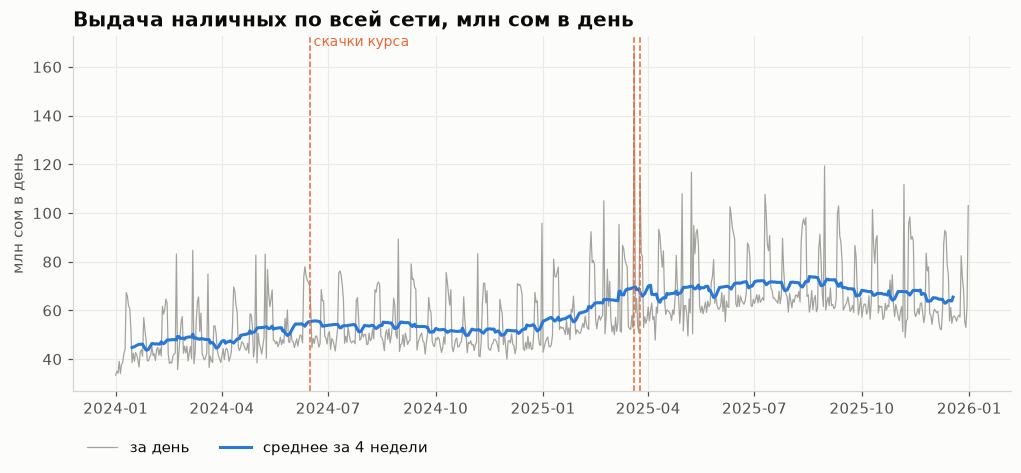

      total_bln  atms  per_atm_day  growth_per_atm_day
year                                                  
2024     18.691   114   475815.611                 NaN
2025     24.414   120   564048.718               0.185

Средняя выдача сети по месяцам (млн):
date
1     49.8
2     55.3
3     57.5
4     57.9
5     60.1
6     62.7
7     62.2
8     63.6
9     61.0
10    58.7
11    59.7
12    59.0

Топ-5 дней по выдаче:
date
2025-03-20    166.2
2025-08-30    119.3
2025-05-08    116.8
2025-03-25    114.3
2025-11-06    111.7


In [7]:
net = daily.groupby("date").agg(cash_out=("cash_out", "sum"), atms=("atm_id", "nunique"))
net["ma28"] = net["cash_out"].rolling(28, center=True).mean()

fig, ax = plt.subplots()
ax.plot(net.index, net.cash_out, color=GRAY, linewidth=0.8, label="за день")
ax.plot(net.index, net.ma28, color=BLUE, label="среднее за 4 недели")
shocks = daily.loc[daily.fx_shock, "date"].drop_duplicates()
for d in shocks:
    ax.axvline(d, color=ORANGE, linewidth=1, linestyle="--")
ax.text(shocks.iloc[0], ax.get_ylim()[1], " скачки курса", color=ORANGE, va="top", fontsize=9)
ax.yaxis.set_major_formatter(mln)
ax.set_ylabel("млн сом в день")
ax.set_title("Выдача наличных по всей сети, млн сом в день")
ax.legend(loc="upper left", bbox_to_anchor=(0, -0.1), ncol=2)
save(fig, "01_trend"); plt.show()

y = daily.assign(year=daily.date.dt.year).groupby("year").agg(
    total_bln=("cash_out", lambda s: s.sum() / 1e9), atms=("atm_id", "nunique"),
    per_atm_day=("cash_out", "mean"))
y["growth_per_atm_day"] = y.per_atm_day.pct_change()
print(y.round(3))
m = net.groupby(net.index.month).cash_out.mean()
print("\nСредняя выдача сети по месяцам (млн):"); print((m / 1e6).round(1).to_string())
print("\nТоп-5 дней по выдаче:"); print((net.cash_out.nlargest(5) / 1e6).round(1).to_string())

**Что видно:** 
- **Спрос растёт.** В 2025 году один банкомат в среднем выдавал за день на **18,5% больше**, чем в 2024-м (564 тыс. против 476 тыс. сом). Вся сеть за год выдала 18,7 млрд сом в 2024 и 24,4 млрд в 2025 (тут ещё и банкоматов стало больше: 114 → 120).
- **Есть сезонность:** январь самый тихий (~50 млн в день по сети), пик летом — в августе ~64 млн.
- **Резкие пики** — это особые дни. Самый большой день за 2 года — **20 марта 2025** (166 млн, почти в 3 раза выше обычного) — день скачка курса доллара.
- **Что это значит для модели:** обучать на 2024 году и проверять на 2025-м нужно аккуратно — уровень спроса сместился. Модель должна учитывать тренд (например, через средние за последние недели).

### 4.2 Дни недели

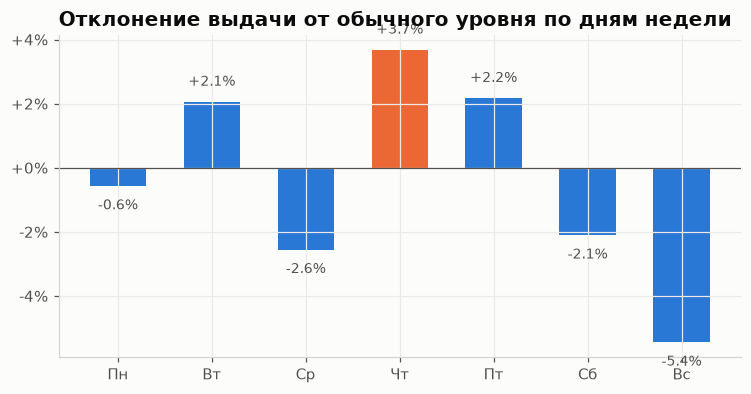

          rel      cash
dow                    
Пн  -0.005706  506846.0
Вт   0.020574  534942.0
Ср  -0.025570  512937.0
Чт   0.036798  548062.0
Пт   0.021740  533523.0
Сб  -0.021058  509012.0
Вс  -0.054484  483995.0

Отклонение по дням недели в разрезе типа точки:
dow                 Пн    Вт    Ср    Чт    Пт    Сб    Вс
atm_type                                                  
highway_gas       -3.5  -0.7 -10.4  -6.7   4.9   0.7   8.2
office_business   30.2  40.4  38.1  26.8  28.1 -66.8 -73.8
pension_social     3.6  -2.5  -1.5   2.2  10.2   7.3  -0.9
residential       -3.5  -3.3  -5.2   1.9  -6.0   9.0   4.0
shopping_mall    -23.7  -8.2 -19.7  -5.9 -18.0  27.2  30.0
tourist_center     2.0 -15.1 -18.5   0.9 -10.1  10.9  17.7
transport_market  -8.9  -1.3  -7.2   3.6   2.1   2.0  -8.6


In [8]:
names = {1: "Пн", 2: "Вт", 3: "Ср", 4: "Чт", 5: "Пт", 6: "Сб", 7: "Вс"}
regular = clean[~clean.is_holiday & ~clean.is_pre_holiday & ~clean.fx_shock]
by_dow = regular.groupby("dow").agg(rel=("rel", "mean"), cash=("cash_out", "mean"))

fig, ax = plt.subplots(figsize=(8, 3.8))
colors = [ORANGE if v == by_dow.rel.max() else BLUE for v in by_dow.rel]
ax.bar(by_dow.index.map(names), by_dow.rel, color=colors, width=0.6)
ax.axhline(0, color=INK2, linewidth=0.8)
ax.yaxis.set_major_formatter(pct)
ax.set_title("Отклонение выдачи от обычного уровня по дням недели")
for x, v in zip(range(7), by_dow.rel):
    ax.text(x, v + (0.004 if v >= 0 else -0.004), f"{v:+.1%}", ha="center",
            va="bottom" if v >= 0 else "top", fontsize=9, color=INK2)
save(fig, "02_dow"); plt.show()
print(by_dow.assign(cash=lambda d: d.cash.round(0)).rename(index=names))

# Отличаются ли дни недели по типам точек?
pivot = regular.pivot_table(index="atm_type", columns="dow", values="rel", aggfunc="mean").rename(columns=names)
print("\nОтклонение по дням недели в разрезе типа точки:"); print((pivot * 100).round(1))

**Что видно:** 
- **По сети в целом дни недели почти не важны:** разница всего ±5% (чуть больше в четверг, меньше в воскресенье).
- **Но это обманчиво — внутри типов точек разница огромная:**
  - банкоматы у **офисов** в выходные выдают на **~70% меньше** (людей в бизнес-центрах нет);
  - в **торговых центрах** наоборот: в выходные **+30%**, в будни ниже обычного;
  - у туристических мест тоже пик в выходные.
- Эти эффекты гасят друг друга, поэтому общая картина ровная.
- **Для модели:** признак «день недели» нужно использовать **вместе с типом банкомата**, иначе модель не увидит эту разницу. LightGBM умеет находить такие сочетания сам.

### 4.3 Праздники, зарплаты, пенсии, Рамадан

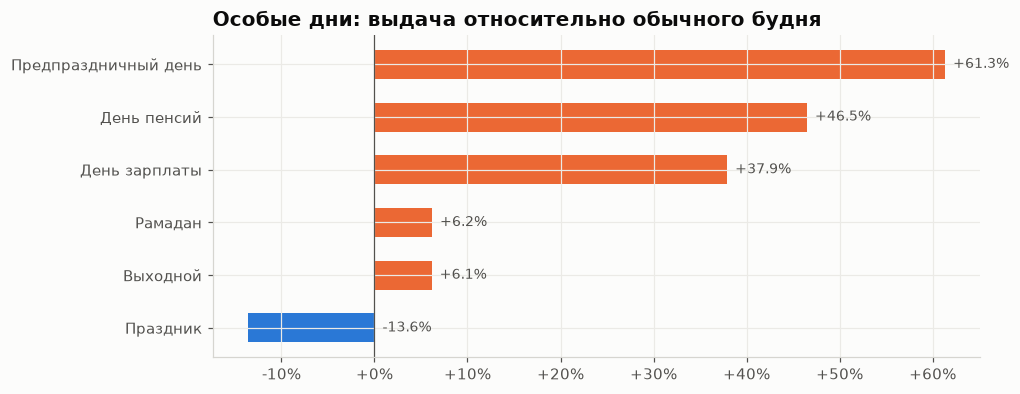

                        rel  дней  vs_обычный_будний
тип дня                                             
Праздник             -0.240    38             -0.136
Выходной             -0.042   207              0.061
Рамадан              -0.041    57              0.062
День зарплаты         0.276   191              0.379
День пенсий           0.362   120              0.465
Предпраздничный день  0.510    15              0.613

Праздники по отдельности (отклонение от обычного уровня):
holiday_name
День Победы                          -31.2
Праздник труда                       -30.2
Новый год                            -28.7
День защитника Отечества             -27.0
День Конституции                     -26.5
День Апрельской народной революции   -25.7
Международный женский день           -25.7
Дни истории и памяти предков         -25.4
Нооруз                               -23.4
Курман айт                           -23.1
Новогодние каникулы                  -23.0
День независимости             

In [9]:
flags = {
    "Праздник": "is_holiday", "Предпраздничный день": "is_pre_holiday",
    "День зарплаты": "is_payday", "День пенсий": "is_pension_day",
    "Рамадан": "is_ramadan", "Выходной": "is_weekend",
}
base = clean[~clean[list(flags.values())].any(axis=1) & ~clean.fx_shock]
rows = []
for label, col in flags.items():
    sub = clean[clean[col] & ~clean.fx_shock]
    rows.append({"тип дня": label, "rel": sub.rel.mean(), "дней": sub.date.nunique()})
special = pd.DataFrame(rows).set_index("тип дня").sort_values("rel")
special["vs_обычный_будний"] = special.rel - base.rel.mean()

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.barh(special.index, special.vs_обычный_будний,
        color=[ORANGE if v > 0 else BLUE for v in special.vs_обычный_будний], height=0.55)
ax.axvline(0, color=INK2, linewidth=0.8)
ax.xaxis.set_major_formatter(pct)
for yv, v in enumerate(special.vs_обычный_будний):
    ax.text(max(v, 0), yv, f"  {v:+.1%}", va="center", ha="left", fontsize=9, color=INK2)
ax.set_title("Особые дни: выдача относительно обычного будня")
save(fig, "03_special_days"); plt.show()
print(special.round(3))

# Какие праздники сильнее всего
hol = clean[clean.is_holiday].groupby("holiday_name").rel.mean().sort_values()
print("\nПраздники по отдельности (отклонение от обычного уровня):"); print((hol * 100).round(1).to_string())

# Пенсии: где сильнее всего
pen = clean[clean.is_pension_day].groupby("atm_type").rel.mean() - base.groupby("atm_type").rel.mean()
print("\nДень пенсий по типам точек (п.п. к обычному будню):"); print((pen * 100).round(1).sort_values().to_string())

**Что видно:** 
*Сравниваем с обычным будним днём без зарплат, пенсий и праздников.*

- **Предпраздничный день — самый сильный эффект: +61%.** Люди снимают наличные заранее, перед длинными выходными.
- **День пенсий: +47%**, а у банкоматов возле Соцфонда и поликлиник — **в 2,5 раза больше** обычного (+154 п.п.). Пенсионеры приходят за деньгами в один день.
- **День зарплаты: +38%.**
- **Сам праздник: −14%** (относительно обычного уровня — −20…−30% почти для всех праздников). Исключение — **Орозо айт**: почти без падения.
- Выходные и Рамадан в целом дают небольшой плюс (~+6%).
- **Для модели:** флаги «предпраздничный день», «пенсии», «зарплата» — одни из самых важных признаков. Они **известны заранее** по календарю, поэтому их можно честно использовать для прогноза.

### 4.4 Температура

Сравниваем банкоматы **на улице** и **в помещениях** (ТЦ, отделения, АЗС): мороз должен сильнее бить по уличным.

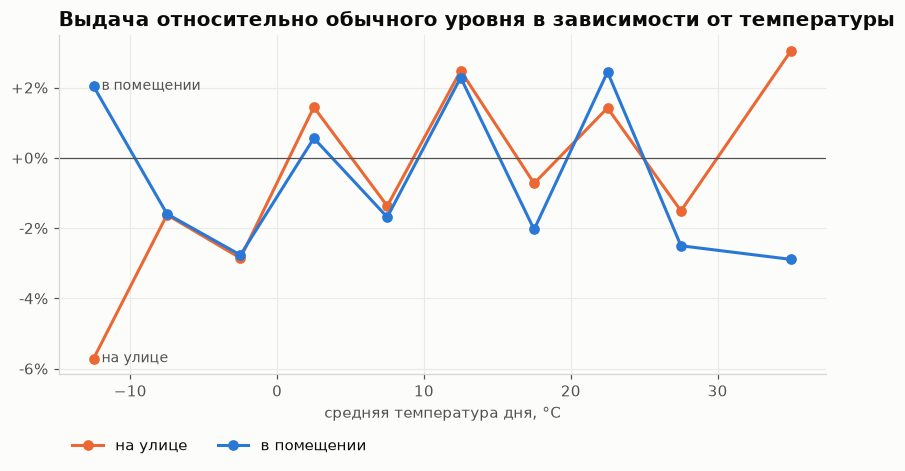

street      в помещении  на улице
temp_bin                         
(-15, -10]          2.0      -5.7
(-10, -5]          -1.6      -1.6
(-5, 0]            -2.8      -2.9
(0, 5]              0.6       1.4
(5, 10]            -1.7      -1.4
(10, 15]            2.3       2.5
(15, 20]           -2.0      -0.7
(20, 25]            2.4       1.4
(25, 30]           -2.5      -1.5
(30, 40]           -2.9       3.0

Дней в каждом диапазоне:
temp_bin
(-30, -15]      0
(-15, -10]      8
(-10, -5]      32
(-5, 0]       100
(0, 5]         93
(5, 10]        80
(10, 15]      109
(15, 20]       96
(20, 25]      116
(25, 30]       91
(30, 40]        6

Мороз 16–17.02.2024:
street
в помещении   -15.2
на улице      -24.8

Снег > 5 мм:
street
в помещении    5.5
на улице      -9.2


In [10]:
clean["street"] = np.where(clean.placement == "street", "на улице", "в помещении")
bins = [-30, -15, -10, -5, 0, 5, 10, 15, 20, 25, 30, 40]
clean["temp_bin"] = pd.cut(clean.temp_avg, bins)
tb = clean.groupby(["temp_bin", "street"], observed=True).rel.mean().unstack()
mid = [b.mid for b in tb.index]

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(mid, tb["на улице"], marker="o", color=ORANGE, label="на улице")
ax.plot(mid, tb["в помещении"], marker="o", color=BLUE, label="в помещении")
ax.axhline(0, color=INK2, linewidth=0.8)
ax.yaxis.set_major_formatter(pct)
ax.set_xlabel("средняя температура дня, °C")
ax.set_title("Выдача относительно обычного уровня в зависимости от температуры")
ax.text(mid[0], tb["на улице"].iloc[0], "  на улице", color=INK2, va="center", fontsize=9)
ax.text(mid[0], tb["в помещении"].iloc[0], "  в помещении", color=INK2, va="center", fontsize=9)
ax.legend(loc="upper left", bbox_to_anchor=(0, -0.15), ncol=2)
save(fig, "04_temperature"); plt.show()
print((tb * 100).round(1))
print("\nДней в каждом диапазоне:"); print(clean.drop_duplicates("date").temp_bin.value_counts(sort=False).to_string())

frost = clean[clean.date.isin(pd.to_datetime(["2024-02-16", "2024-02-17"]))]
print("\nМороз 16–17.02.2024:"); print((frost.groupby("street").rel.mean() * 100).round(1).to_string())
print("\nСнег > 5 мм:"); print((clean[clean.snowfall_mm > 5].groupby("street").rel.mean() * 100).round(1).to_string())

**Что видно:** 
- **В обычном диапазоне температура почти не влияет** — колебания ±3%, это в пределах шума.
- **Влияют только экстремальные дни.** Во время сильного мороза **16–17 февраля 2024** уличные банкоматы выдали на **25% меньше** обычного, банкоматы в помещениях — на 15% меньше. В снегопад (> 5 мм) уличные теряют ~9%, а в помещениях выдача даже немного выше (+5%) — люди идут снимать деньги туда, где тепло.
- **Для модели:** вместо «температуры как есть» лучше сделать признаки «сильный мороз» и «снегопад» и учитывать, на улице ли банкомат. Но таких дней мало, так что общий вклад погоды небольшой.

### 4.5 Скачки курса доллара

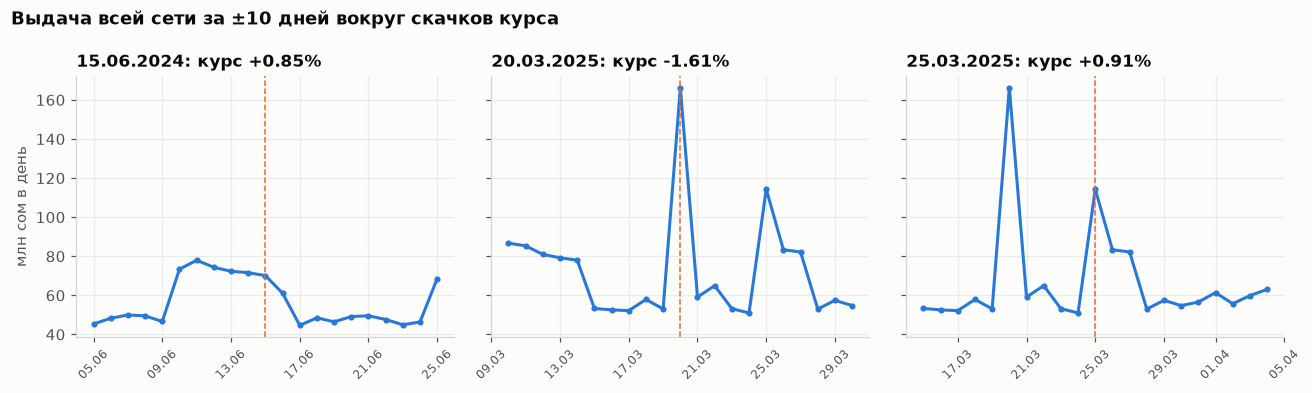

2024-06-15 (+0.85%):  д0: x1.43 д1: x1.25 д2: x0.91 д3: x0.99 д4: x0.95
2025-03-20 (-1.61%):  д0: x2.95 д1: x1.05 д2: x1.15 д3: x0.94 д4: x0.90
2025-03-25 (+0.91%):  д0: x1.95 д1: x1.42 д2: x1.41 д3: x0.91 д4: x0.98

Корреляция |изменение курса| и отклонения выдачи в обычные дни: 0.092


In [11]:
ev = pd.read_parquet(RAW / "labels" / "events.parquet")
fig, axes = plt.subplots(1, len(ev), figsize=(12, 3.6), sharey=True)
for ax, (_, e) in zip(axes, ev.iterrows()):
    w = net.loc[e.date - pd.Timedelta(days=10): e.date + pd.Timedelta(days=10)]
    ax.plot(w.index, w.cash_out, color=BLUE, marker="o", markersize=3)
    ax.axvline(e.date, color=ORANGE, linestyle="--", linewidth=1)
    ax.set_title(f"{e.date:%d.%m.%Y}: курс {e.fx_change_pct:+.2f}%", fontsize=11)
    ax.tick_params(axis="x", labelrotation=45, labelsize=8)
    ax.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%d.%m"))
axes[0].yaxis.set_major_formatter(mln); axes[0].set_ylabel("млн сом в день")
fig.suptitle("Выдача всей сети за ±10 дней вокруг скачков курса", x=0.01, ha="left", fontweight="bold")
fig.tight_layout(); save(fig, "05_fx_shocks"); plt.show()

for _, e in ev.iterrows():
    before = net.loc[e.date - pd.Timedelta(days=14): e.date - pd.Timedelta(days=1), "cash_out"].median()
    print(f"{e.date:%Y-%m-%d} ({e.fx_change_pct:+.2f}%): ",
          " ".join(f"д{k}: x{net.cash_out.get(e.date + pd.Timedelta(days=k), np.nan) / before:.2f}" for k in range(0, 5)))

# Обычные изменения курса (без шоков): есть ли связь?
nd = net.join(daily.drop_duplicates("date").set_index("date")[["fx_change_pct", "fx_shock"]])
nd["rel"] = nd.cash_out / nd.cash_out.rolling(29, center=True, min_periods=10).median() - 1
calm = nd[~nd.fx_shock]
print("\nКорреляция |изменение курса| и отклонения выдачи в обычные дни:",
      round(calm.fx_change_pct.abs().corr(calm.rel), 3))

**Что видно:** 
- **Скачок курса — это «набег» на банкоматы:** в день события выдача по сети резко подскакивает:
  - 15.06.2024 (+0,85%) — в **1,4 раза**;
  - 20.03.2025 (−1,61%) — почти в **3 раза**, самый большой день за 2 года;
  - 25.03.2025 (+0,91%) — почти в **2 раза**, и ещё 2 дня держится на +40%.
- Через 2–3 дня всё возвращается к норме.
- **Обычные мелкие колебания курса на спрос не влияют** (корреляция 0,09 — практически ноль).
- **Для модели:** такие дни **нельзя предсказать заранее** — курс завтрашнего дня неизвестен. Значит, на них модель будет ошибаться, и это нормально. Важно, чтобы эти 3 дня не «сломали» обучение: их стоит пометить флагом и, возможно, исключить при оценке качества.

### 4.6 Районы и типы банкоматов

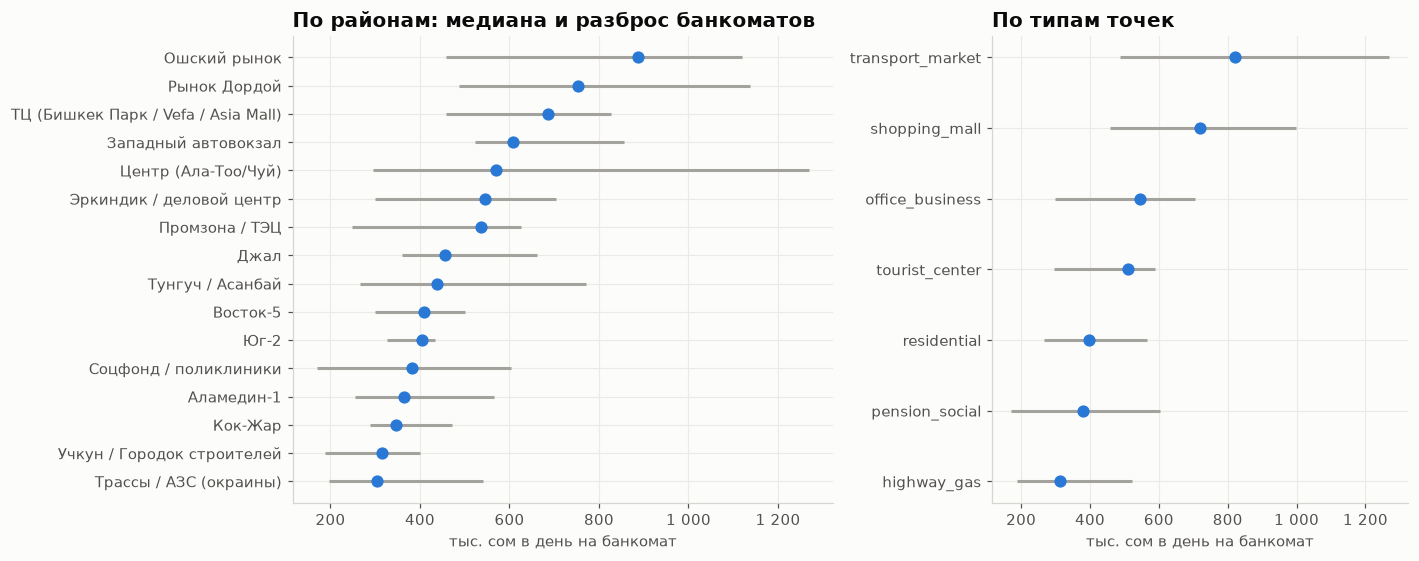

                                     median    min     max  count
district_name                                                    
Трассы / АЗС (окраины)                303.0  197.0   541.0      8
Учкун / Городок строителей            315.0  188.0   401.0      5
Кок-Жар                               347.0  287.0   471.0      7
Аламедин-1                            363.0  256.0   565.0      9
Соцфонд / поликлиники                 382.0  170.0   604.0      7
Юг-2                                  404.0  327.0   434.0      5
Восток-5                              409.0  298.0   501.0      7
Тунгуч / Асанбай                      438.0  267.0   771.0      4
Джал                                  456.0  359.0   661.0      4
Промзона / ТЭЦ                        537.0  248.0   625.0      5
Эркиндик / деловой центр              544.0  299.0   704.0     13
Центр (Ала-Тоо/Чуй)                   569.0  295.0  1269.0     15
Западный автовокзал                   608.0  522.0   856.0      5
ТЦ (Бишкек

In [12]:
by_atm = clean.groupby(["atm_id", "district_name", "zone_type", "atm_type", "placement"], as_index=False).cash_out.mean()

fig, axes = plt.subplots(1, 2, figsize=(13, 5.2), gridspec_kw={"width_ratios": [1.3, 1]})
d = by_atm.groupby("district_name").cash_out.agg(["median", "min", "max", "count"]).sort_values("median")
ax = axes[0]
ax.hlines(d.index, d["min"], d["max"], color=GRAY, linewidth=2)
ax.plot(d["median"], d.index, "o", color=BLUE, markersize=7)
ax.xaxis.set_major_formatter(thousands); ax.set_xlabel("тыс. сом в день на банкомат")
ax.set_title("По районам: медиана и разброс банкоматов")

t = by_atm.groupby("atm_type").cash_out.agg(["median", "min", "max", "count"]).sort_values("median")
ax = axes[1]
ax.hlines(t.index, t["min"], t["max"], color=GRAY, linewidth=2)
ax.plot(t["median"], t.index, "o", color=BLUE, markersize=7)
ax.xaxis.set_major_formatter(thousands); ax.set_xlabel("тыс. сом в день на банкомат")
ax.set_title("По типам точек")
fig.tight_layout(); save(fig, "06_districts_types"); plt.show()

print((d.assign(**{c: d[c] / 1e3 for c in ["median", "min", "max"]})).round(0).to_string())
print(); print((t.assign(**{c: t[c] / 1e3 for c in ["median", "min", "max"]})).round(0).to_string())
print("\nСамый загруженный / самый тихий банкомат (тыс. сом/день):",
      round(by_atm.cash_out.max() / 1e3), "/", round(by_atm.cash_out.min() / 1e3),
      f"— разница x{by_atm.cash_out.max() / by_atm.cash_out.min():.0f}")
print("Доля разброса, объясняемая типом точки (R²):",
      round(1 - by_atm.groupby('atm_type').cash_out.transform(lambda s: s - s.mean()).var() / by_atm.cash_out.var(), 2))
print("Доля разброса, объясняемая районом (R²):",
      round(1 - by_atm.groupby('district_name').cash_out.transform(lambda s: s - s.mean()).var() / by_atm.cash_out.var(), 2))

**Что видно:** 
- **Банкоматы очень разные:** самый загруженный выдаёт ~1,25 млн сом в день, самый тихий — ~170 тыс. Разница **в 7 раз**.
- **Главное — тип точки.** Лидеры — **рынки и транспорт** (медиана ~810 тыс./день, Ошский рынок и Дордой — самые загруженные районы) и **торговые центры** (~710 тыс.). Меньше всего — **АЗС на трассах** (~310 тыс.) и банкоматы у Соцфонда/поликлиник.
- Тип точки объясняет **~67% разницы** между банкоматами, район — ~54% (они пересекаются: на рынках стоят «рыночные» банкоматы).
- Внутри одного района разброс тоже большой (в Центре — от 290 тыс. до 1,25 млн), поэтому одного района мало.
- **Для модели:** тип точки и район — обязательные признаки. А ещё лучше — **история самого банкомата** (его средняя выдача за прошлые недели): она сразу учитывает всё, что делает его особенным.

### 4.7 Как простои и пустые кассеты влияют на выдачу

Сравниваем выдачу в день сбоя с обычным уровнем того же банкомата.

без денег — по длительности: {'0–2ч': '+86% (n=77.0)', '2–4ч': '+103% (n=57.0)', '4–8ч': '+109% (n=88.0)', '8–12ч': '+41% (n=53.0)', '12–24ч': '+24% (n=6.0)'}
простой — по длительности: {'0–2ч': '-8% (n=259.0)', '2–4ч': '-17% (n=221.0)', '4–8ч': '-27% (n=308.0)', '8–12ч': '-64% (n=1.0)', '12–24ч': '+21% (n=8.0)'}


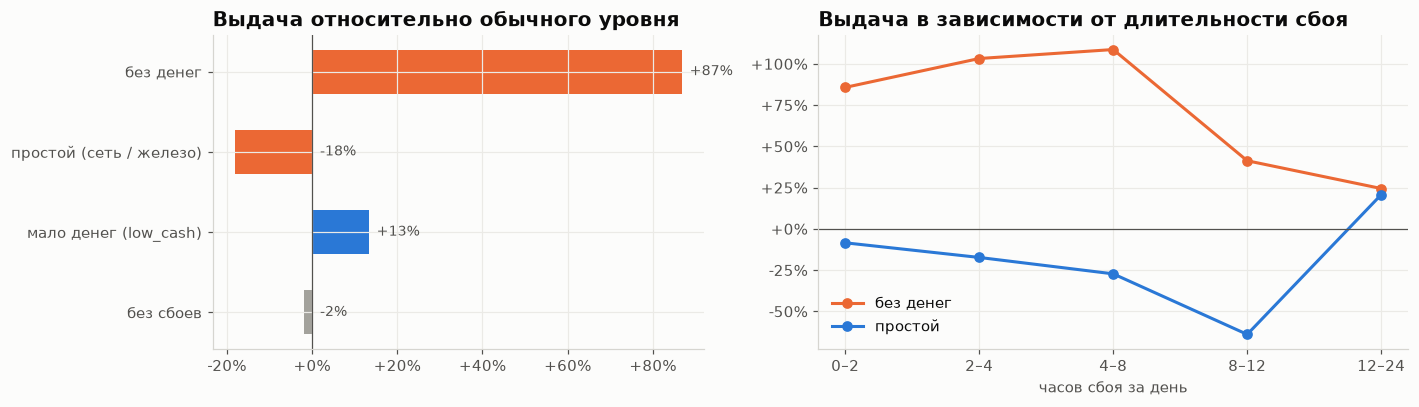

                          rel   days  declines
тип дня                                       
без сбоев                -1.9  72772       6.5
мало денег (low_cash)    13.3   8716       6.5
простой (сеть / железо) -18.1    796      22.0
без денег                86.8    281      19.7

Оценка недовыданных денег из-за сбоев за 2 года: 124 млн сом (0.3% от всей выдачи)
Банкоматы с наибольшим числом дней без денег:
atm_id    atm_type        
ATM-0089  transport_market    25
ATM-0080  office_business     22
ATM-0054  office_business     20
ATM-0090  office_business     17
ATM-0117  office_business     17


In [13]:
d2 = daily[daily.baseline.gt(0)].copy()
d2["тип дня"] = np.select(
    [d2.is_out_of_cash, d2.is_down, d2.low_cash_hours > 0],
    ["без денег", "простой (сеть / железо)", "мало денег (low_cash)"], "без сбоев")
order = ["без сбоев", "мало денег (low_cash)", "простой (сеть / железо)", "без денег"]
g = d2.groupby("тип дня").agg(rel=("rel", "mean"), days=("rel", "size"),
                              declines=("decline_share", "mean")).reindex(order)

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), gridspec_kw={"width_ratios": [1, 1.2]})
ax = axes[0]
ax.barh(g.index, g.rel, color=[GRAY, BLUE, ORANGE, ORANGE], height=0.55)
ax.axvline(0, color=INK2, linewidth=0.8); ax.xaxis.set_major_formatter(pct)
for yv, v in enumerate(g.rel):
    ax.text(max(v, 0), yv, f"  {v:+.0%}", va="center", ha="left", fontsize=9, color=INK2)
ax.set_title("Выдача относительно обычного уровня")

ax = axes[1]
for col, color, label in [("out_of_cash_hours", ORANGE, "без денег"), ("down_hours", BLUE, "простой")]:
    s = d2[d2[col] > 0]
    hb = s.groupby(pd.cut(s[col], [0, 2, 4, 8, 12, 24]), observed=True).rel.agg(["mean", "size"])
    print(label, "— по длительности:", {f"{int(i.left)}–{int(i.right)}ч": f"{m:+.0%} (n={n})" for i, (m, n) in hb.iterrows()})
    hb = hb["mean"]
    ax.plot([f"{int(i.left)}–{int(i.right)}" for i in hb.index], hb.values, marker="o", color=color, label=label)
ax.axhline(0, color=INK2, linewidth=0.8); ax.yaxis.set_major_formatter(pct)
ax.set_xlabel("часов сбоя за день"); ax.set_title("Выдача в зависимости от длительности сбоя")
ax.legend(loc="lower left")
fig.tight_layout(); save(fig, "07_disruptions"); plt.show()

print(g.assign(rel=lambda x: (x.rel * 100).round(1), declines=lambda x: (x.declines * 100).round(1)))
lost = (d2.loc[d2.is_disrupted, "baseline"] - d2.loc[d2.is_disrupted, "cash_out"]).clip(lower=0).sum()
print(f"\nОценка недовыданных денег из-за сбоев за 2 года: {lost / 1e6:,.0f} млн сом "
      f"({lost / daily.cash_out.sum():.1%} от всей выдачи)")
print("Банкоматы с наибольшим числом дней без денег:")
print(daily[daily.is_out_of_cash].groupby(["atm_id", "atm_type"]).size().nlargest(5).to_string())

**Что видно:** 
- **Простой (сеть или поломка) снижает выдачу:** в среднем **−18%** за день, и чем дольше простой, тем больше потеря (до 2 ч — −8%, 4–8 ч — −27%). Доля отказов в такие дни — 22% (в обычный день 6,5%). *Простоев длиннее 8 ч всего 9 — по ним выводы делать нельзя.*
- **Неожиданный результат: в дни, когда банкомат опустел, он выдал на 87% больше обычного.** Логика обратная: банкомат пустеет **именно потому**, что в этот день был наплыв клиентов. Он выдал всё, что было, а потом отказывал (доля отказов ~20%).
- **Важно:** в такие дни мы видим не настоящий спрос, а **только то, что успели выдать**. Настоящий спрос был ещё выше. Если учить модель на этих днях как на обычных, она будет **недооценивать** пиковый спрос.
- Чаще всего пустеют банкоматы на **рынках и у офисов** — там самые большие пики.
- Похожая картина с low_cash (+13%): денег становится мало после загруженных дней.
- **Для модели:** дни сбоев оставляем, но с флагом; при обучении либо исключаем, либо даём им меньший вес. И это прямой бизнес-аргумент проекта: **хороший прогноз = меньше пустых банкоматов в пиковые дни**.

## 5. Сохраняем агрегат

In [14]:
to_save = daily.drop(columns=["baseline", "rel"])
to_save.to_parquet(OUT / "daily.parquet", index=False)
print(f"Сохранено: {OUT / 'daily.parquet'}")
print(f"{len(to_save):,} строк × {to_save.shape[1]} колонок".replace(",", " "))
print(list(to_save.columns))

Сохранено: /Users/aza/Projects/atm-cash-forecast/data/processed/daily.parquet
82 565 строк × 39 колонок
['atm_id', 'date', 'cash_out', 'n_txn', 'n_cash_txn', 'decline_share', 'n_declined_no_cash', 'out_of_cash_hours', 'down_hours', 'low_cash_hours', 'is_out_of_cash', 'is_down', 'is_disrupted', 'dow', 'is_weekend', 'is_holiday', 'holiday_name', 'is_pre_holiday', 'is_ramadan', 'is_pension_day', 'is_payday', 'season', 'temp_avg', 'precip_mm', 'snowfall_mm', 'wind_max', 'usd_kgs_rate', 'fx_change_pct', 'fx_shock', 'district_id', 'district_name', 'zone_type', 'atm_type', 'placement', 'is_24_7', 'is_recycler', 'supports_fx', 'cash_capacity', 'install_date']


## 6. Итог для созвона

**Что мы узнали о спросе на наличные:**

1. **Спрос растёт** — за год +18,5% на банкомат, плюс летний пик и январский спад.
2. **Главное, что определяет выдачу, — сам банкомат:** где он стоит и какого типа точка. Рынки и ТЦ выдают в 2–3 раза больше, чем АЗС на окраинах.
3. **Календарь даёт сильные и предсказуемые всплески:** предпраздничный день +61%, пенсии +47% (у Соцфонда — в 2,5 раза), зарплата +38%. Праздник сам по себе — минус 20–30%.
4. **День недели работает по-разному для разных точек:** офисы в выходные почти пустые, ТЦ — наоборот, пик.
5. **Погода важна только в экстремальные дни** (сильный мороз — уличные банкоматы −25%).
6. **Скачки курса вызывают набег** (до ×3 за день), но их нельзя предсказать заранее.
7. **Сбои:** простой снижает выдачу, а пустые банкоматы скрывают реальный спрос — в такие дни он был выше, чем мы видим.

**Что делаем дальше (план модели):**
- Целевая переменная — `cash_out` по банкомату на день вперёд.
- Признаки: история банкомата (выдача вчера, неделю назад, средние за 7/28 дней), календарь (предпраздник, пенсии, зарплата, праздник, день недели), тип точки и район, мороз/снег.
- Дни сбоев и скачков курса — с флагами, не учим на них как на обычных.
- Сначала простые базовые прогнозы (как неделю назад, среднее по дню недели), потом LightGBM. Обучаем на 2024, проверяем на 2025.

Графики для презентации сохранены в `reports/figures/`.